# JobGuard AI - Milestone 2: Dataset Exploration

**Project:** Detecting Fraudulent Job Postings Using Machine Learning and NLP

**Purpose of this notebook:** understand the EMSCAD dataset *before* building anything. Good machine learning starts with knowing your data.

We will answer these questions:
1. How big is the dataset and what columns does it have?
2. What does the target column `fraudulent` mean, and how balanced is it?
3. Which columns have missing values?
4. Which text columns could be used for NLP later?
5. Do the structured columns (logo, telecommuting, ...) show any pattern with fraud?
6. Are there duplicate rows?

**No models are trained in this notebook. No TF-IDF, no train/test split.** We only look at the data.

## 1. Import libraries

We only need three libraries for exploration:
- **pandas** - tables (DataFrames) and data analysis
- **numpy** - numeric helpers such as averages
- **matplotlib** - charts

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

We also define where the data lives and where charts are saved. The notebook is inside `notebooks/`, so `..` means "go up one folder to the project root".

In [2]:
DATA_PATH = Path("../data/raw/fake_job_postings.csv")
FIGURES_DIR = Path("../results/figures")
METRICS_DIR = Path("../results/metrics")

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)

## 2. Load the dataset

`pd.read_csv` reads the CSV file into a **DataFrame** (a table). We call it `df`.
If the file is missing we stop with a helpful message instead of a confusing error.

In [3]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH.resolve()}\n"
        "Place the EMSCAD CSV at data/raw/fake_job_postings.csv"
    )

df = pd.read_csv(DATA_PATH)

## 3. First look at the data

### 3.1 Shape
Shape is `(number of rows, number of columns)`. Each row is one job posting.

In [4]:
print("Shape (rows, columns):", df.shape)
print("Number of job postings:", df.shape[0])
print("Number of columns:", df.shape[1])

Shape (rows, columns): (17880, 18)
Number of job postings: 17880
Number of columns: 18


### 3.2 First five rows

In [5]:
df.head(5)

,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0
3,4,Account Executive - Washington DC,"US, DC, Washington",Sales,NaN,Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Our culture is anything but corporate—we have ...,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0
4,5,Bill Review Manager,"US, FL, Fort Worth",NaN,NaN,SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,Full Benefits Offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0


### 3.3 Column names

In [6]:
for column_name in df.columns:
    print(column_name)

job_id
title
location
department
salary_range
company_profile
description
requirements
benefits
telecommuting
has_company_logo
has_questions
employment_type
required_experience
required_education
industry
function
fraudulent


### 3.4 Data types and basic information

`df.info()` lists each column's data type and how many values are **non-null** (not missing).
In pandas, text columns appear as `object` (or `str` in newer pandas versions) and whole-number columns as `int64`.

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17880 entries, 0 to 17879
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   job_id               17880 non-null  int64
 1   title                17880 non-null  str  
 2   location             17534 non-null  str  
 3   department           6333 non-null   str  
 4   salary_range         2868 non-null   str  
 5   company_profile      14572 non-null  str  
 6   description          17879 non-null  str  
 7   requirements         15184 non-null  str  
 8   benefits             10668 non-null  str  
 9   telecommuting        17880 non-null  int64
 10  has_company_logo     17880 non-null  int64
 11  has_questions        17880 non-null  int64
 12  employment_type      14409 non-null  str  
 13  required_experience  10830 non-null  str  
 14  required_education   9775 non-null   str  
 15  industry             12977 non-null  str  
 16  function             11425 non-nu

## 4. The target column: `fraudulent`

In supervised learning the **target** (label) is what we want the model to predict. Here it is `fraudulent`:

| Value | Meaning |
|-------|---------|
| 0 | legitimate job posting |
| 1 | fraudulent job posting |

The CSV only stores the numbers 0 and 1; the meaning comes from the dataset's documentation. We can still check two things from the data itself: (1) the column contains only 0 and 1, and (2) real examples of each label read the way we expect.

In [8]:
print("Unique values in 'fraudulent':", sorted(df["fraudulent"].unique().tolist()))
print("Missing values in 'fraudulent':", df["fraudulent"].isna().sum())

Unique values in 'fraudulent': [0, 1]
Missing values in 'fraudulent': 0


Now we read one posting from each class. A random sample is used, so re-running with a different `random_state` shows other examples. Read them and judge whether label `1` really looks suspicious.

In [9]:
for label_value, label_name in [(0, "LEGITIMATE"), (1, "FRAUDULENT")]:
    example = df[df["fraudulent"] == label_value].sample(1, random_state=1).iloc[0]
    print(f"===== fraudulent = {label_value} ({label_name}) =====")
    print("Title      :", example["title"])
    print("Description:", str(example["description"])[:400], "...")
    print()

===== fraudulent = 0 (LEGITIMATE) =====
Title      : Web Developer, HTML | CSS | JavaScript
Description: PINT is seeking an associate web developer with strong client-side coding ability and an eye for web layout and design.  PINT Devs are part of a team of industry veterans developing sites, building custom content management system modules and performing client-side maintenance tasks on hundreds of sites across a variety of industries. The successful candidate is someone who is passionate about dev ...

===== fraudulent = 1 (FRAUDULENT) =====
Title      : Clinical Director - Surgical Services  
Description: Apply using below link#URL_cf955625ede97e1444d64f9efbdd5c61a812c7444ce84be35525380f7549cf19#Clinical Director - Surgical ServicesPocono Health System (PHS) is unwavering in our commitment to meeting the diverse healthcare needs for the people of Monroe County, PA. Our continued growth has created opportunities for a dynamic and experienced Nurse Leader to join us in a senior level

**Note:** fraudulent postings are often written to look professional, so reading one example does not always make the label obvious. That is exactly why we want a machine-learning model to look for patterns across thousands of postings.

## 5. Class distribution

How many postings are legitimate and how many are fraudulent? `value_counts()` counts each label. Dividing by the total number of rows gives percentages.

In [10]:
class_counts = df["fraudulent"].value_counts().sort_index()
total_postings = len(df)

legitimate_count = class_counts[0]
fraudulent_count = class_counts[1]
legitimate_percent = legitimate_count / total_postings * 100
fraudulent_percent = fraudulent_count / total_postings * 100

print(f"Legitimate postings (0): {legitimate_count:,}  ({legitimate_percent:.2f}%)")
print(f"Fraudulent postings (1): {fraudulent_count:,}  ({fraudulent_percent:.2f}%)")
print(f"Total: {total_postings:,}")
print(f"There are about {legitimate_count / fraudulent_count:.1f} legitimate postings for every 1 fraudulent posting.")

Legitimate postings (0): 17,014  (95.16%)
Fraudulent postings (1): 866  (4.84%)
Total: 17,880
There are about 19.6 legitimate postings for every 1 fraudulent posting.


### Why class imbalance matters

When one class is much rarer than the other, the dataset is **imbalanced**. This is the most important idea in this project.

Imagine a "model" that ignores the text and always answers *legitimate*. On an imbalanced dataset it would be right most of the time, so its **accuracy would look great**, yet it would **catch zero fraudulent postings**. That would be useless for protecting job seekers.

So later we will **not rely on accuracy alone**. For the fraudulent class we will look at:

- **Precision** - of the postings we flagged as fraud, how many really were fraud?
- **Recall** - of all the real fraud postings, how many did we catch?
- **F1-score** - one number that balances precision and recall.
- **Confusion matrix** - a table of correct and incorrect predictions for each class.

(We are *not* computing any of these now, since there are no models yet.)

The next cell shows how large that "always say legitimate" accuracy would be. This is simple arithmetic on the class percentages, not a trained model.

In [11]:
print(f"A rule that always says 'legitimate' would be correct {legitimate_percent:.2f}% of the time,")
print("but it would catch none of the fraudulent postings (by definition, it never says 'fraud').")

A rule that always says 'legitimate' would be correct 95.16% of the time,
but it would catch none of the fraudulent postings (by definition, it never says 'fraud').


### Bar chart of the two classes

The chart is saved to `results/figures/class_distribution.png` so we can reuse it in the presentation.

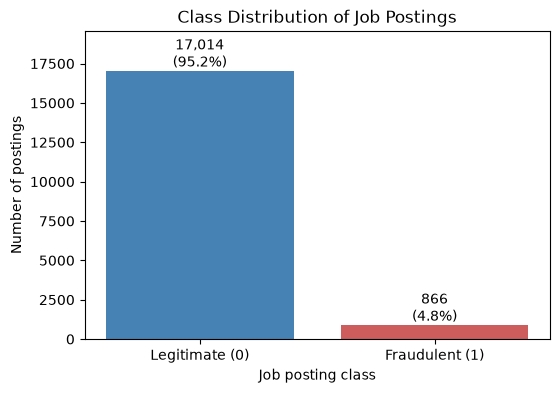

In [12]:
class_names = ["Legitimate (0)", "Fraudulent (1)"]
class_values = [legitimate_count, fraudulent_count]

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(class_names, class_values, color=["steelblue", "indianred"])
ax.bar_label(bars, labels=[f"{legitimate_count:,}\n({legitimate_percent:.1f}%)",
                           f"{fraudulent_count:,}\n({fraudulent_percent:.1f}%)"])
ax.set_title("Class Distribution of Job Postings")
ax.set_xlabel("Job posting class")
ax.set_ylabel("Number of postings")
ax.set_ylim(0, max(class_values) * 1.15)   # extra room for the labels

fig.savefig(FIGURES_DIR / "class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Missing values

Real-world data is rarely complete. `df.isna()` marks missing cells and `.sum()` counts them per column. We convert the counts to percentages and sort from most missing to least missing.

Why it matters: models cannot read a missing value, so we must decide how to handle each column later. For text columns the usual safe choice is to treat a missing value as an empty string.

In [13]:
missing_count = df.isna().sum()
missing_percent = missing_count / len(df) * 100

missing_table = pd.DataFrame({
    "missing_count": missing_count,
    "missing_percent": missing_percent.round(2),
})
missing_table = missing_table.sort_values("missing_percent", ascending=False)

missing_table.to_csv(METRICS_DIR / "missing_values.csv")
missing_table

,missing_count,missing_percent
salary_range,15012,83.96
department,11547,64.58
required_education,8105,45.33
benefits,7212,40.34
required_experience,7050,39.43
function,6455,36.10
industry,4903,27.42
employment_type,3471,19.41
company_profile,3308,18.50
requirements,2696,15.08


## 7. Text columns for NLP

The project focuses on **NLP (Natural Language Processing)**: teaching a model to learn from written text. These five columns hold the main text of a posting:

- `title`
- `company_profile`
- `description`
- `requirements`
- `benefits`

For each one we show: how many values are missing, the average text length (in characters and words), and two example entries (shortened to 250 characters).

In [14]:
text_columns = ["title", "company_profile", "description", "requirements", "benefits"]

for column_name in text_columns:
    present_text = df[column_name].dropna()           # only rows that have text
    char_lengths = present_text.str.len()
    word_counts = present_text.str.split().str.len()

    print("=" * 70)
    print(f"Column: {column_name}")
    print(f"  Missing values : {df[column_name].isna().sum():,} "
          f"({df[column_name].isna().mean() * 100:.1f}%)")
    print(f"  Average length : {np.mean(char_lengths):.0f} characters, {np.mean(word_counts):.0f} words")
    print(f"  Median length  : {np.median(char_lengths):.0f} characters")
    print("  Two examples:")
    for example_text in present_text.sample(2, random_state=42):
        print("   -", example_text[:250].replace("\n", " "), "...")

Column: title
  Missing values : 0 (0.0%)
  Average length : 29 characters, 4 words
  Median length  : 25 characters
  Two examples:
   - Python Engineer ...
   - Entry Level Sales ...


Column: company_profile
  Missing values : 3,308 (18.5%)


  Average length : 762 characters, 114 words
  Median length  : 684 characters
  Two examples:
   - Being into the IT domain for over 4 years, Walkover specializes in web based application development and mobile application development. It has been creating innovative products since it was founded and continues to introduce new products from time t ...
   - Green Street Advisors is the industry leader in real estate and real estate investment trust (REITs) research for over 25 years. Our dedicated research professionals generally cover far fewer companies per researcher than is typical for a securities  ...


Column: description
  Missing values : 1 (0.0%)
  Average length : 1218 characters, 170 words
  Median length  : 1017 characters
  Two examples:
   - Stylect is a dynamic startup that helps helps women discover and buy shoes. We’re a small team based in London that has previously worked at Google, Techstars, Pixelmator and Rocket Internet.We place a high premium on simplicity no matter what we’re  ...
   - General Summary: Achieves maximum sales profitability, growth and account penetration within an assigned territory and/or market segment by effectively selling the company’s products and/or related services. Personally contacts and secures new busine ...


Column: requirements
  Missing values : 2,696 (15.1%)
  Average length : 695 characters, 92 words
  Median length  : 562 characters
  Two examples:
   - Our desired candidate is an enthusiastic individual with a passion for digital, who is in the process of finishing their HBO or academic studies. Ideally, Dutch is your first-language but you are confident in your ability to speak, read, and write En ...
   - The Musts:You love to write, and create content that people love to share.Excellent communication skills – written and verbal.You think big, and enjoy moving fast.You have a natural willingness to learn something new. Every day.You like people, and e ...
Column: benefits
  Missing values : 7,212 (40.3%)
  Average length : 350 characters, 50 words
  Median length  : 237 characters
  Two examples:
   - Auto allowance40 vacation hours after 6 months of employment, 80 vacation hours after 1 year of employment6 paid holidays as well as an anniversary holiday benefitPaid personal and si

The next table puts the five columns side by side. We will also check whether *missing* text is more common among fraudulent postings: for each column, the share of missing values within each class.

In [15]:
text_summary = pd.DataFrame({
    "missing_percent": df[text_columns].isna().mean() * 100,
    "avg_characters": [df[c].dropna().str.len().mean() for c in text_columns],
}).round(1)
text_summary

,missing_percent,avg_characters
title,0.0,28.5
company_profile,18.5,761.9
description,0.0,1218.1
requirements,15.1,694.9
benefits,40.3,350.1


In [16]:
# Percent of postings with a missing value, separately for each class
missing_by_class = df[text_columns].isna().groupby(df["fraudulent"]).mean() * 100
missing_by_class.index = ["Legitimate (0)", "Fraudulent (1)"]
missing_by_class.round(1)

,title,company_profile,description,requirements,benefits
Legitimate (0),0.0,16.0,0.0,14.9,40.2
Fraudulent (1),0.0,67.8,0.1,17.8,42.0


## 8. Structured columns

Besides text, each posting has structured fields. We only *look* at them here; no transformations.

**Yes/no columns** (stored as 1 = yes, 0 = no):
`telecommuting`, `has_company_logo`, `has_questions`

**Category columns** (text labels):
`employment_type`, `required_experience`, `required_education`, `industry`, `function`

For each column we show the **5 most common values**, with:
- `postings` - how many postings have that value
- `fraud_rate_%` - the percent of those postings that are fraudulent

`NaN` in the first column means the value is missing.

In [17]:
structured_columns = ["telecommuting", "has_company_logo", "has_questions",
                      "employment_type", "required_experience", "required_education",
                      "industry", "function"]

for column_name in structured_columns:
    table = df.groupby(column_name, dropna=False)["fraudulent"].agg(postings="count", fraud_rate="mean")
    table["fraud_rate_%"] = (table["fraud_rate"] * 100).round(2)
    table = table.drop(columns="fraud_rate").sort_values("postings", ascending=False)

    print("=" * 70)
    print(f"Column: {column_name}   "
          f"({df[column_name].nunique()} distinct values, {df[column_name].isna().sum():,} missing)")
    print(table.head(5))

Column: telecommuting   (2 distinct values, 0 missing)
               postings  fraud_rate_%
telecommuting                        
0                 17113          4.69
1                   767          8.34
Column: has_company_logo   (2 distinct values, 0 missing)
                  postings  fraud_rate_%
has_company_logo                        
1                    14220          1.99
0                     3660         15.93
Column: has_questions   (2 distinct values, 0 missing)
               postings  fraud_rate_%
has_questions                        
0                  9088          6.78
1                  8792          2.84
Column: employment_type   (5 distinct values, 3,471 missing)
                 postings  fraud_rate_%
employment_type                        
Full-time           11620          4.22
NaN                  3471          6.94
Contract             1524          2.89
Part-time             797          9.28
Temporary             241          0.83
Column: required_experi

## 9. Duplicate rows

If the same posting appears twice, one copy could land in the training set and the other in the test set later. The model would then be "tested" on something it has already seen, which makes results look better than they really are (this is called **data leakage**).

Every row has a unique `job_id`, so we check duplicates both with and without that ID column.

In [18]:
duplicates_with_id = df.duplicated().sum()
duplicates_without_id = df.drop(columns="job_id").duplicated().sum()

print("Duplicate rows (all columns):          ", duplicates_with_id)
print("Duplicate rows (ignoring job_id):      ", duplicates_without_id)

Duplicate rows (all columns):           0
Duplicate rows (ignoring job_id):       281


In [19]:
# If duplicates exist, which classes do the extra copies belong to?
duplicate_rows = df[df.drop(columns="job_id").duplicated()]
print("Class counts among the duplicated rows:")
print(duplicate_rows["fraudulent"].value_counts().sort_index())

Class counts among the duplicated rows:
fraudulent
0    271
1     10
Name: count, dtype: int64


### Do identical postings ever have different labels?

The check above compared all columns except `job_id`, which includes the label itself. A stricter question: are there postings whose **five text fields are identical** but whose labels disagree? That would be a contradiction in the data.

We also calculate how large the duplicate problem is compared with the whole dataset.

In [20]:
extra_copies = duplicates_without_id                                  # copies beyond the first one
rows_involved = df.drop(columns="job_id").duplicated(keep=False).sum()  # every row that has a twin

print(f"Extra duplicate copies: {extra_copies} ({extra_copies / len(df) * 100:.2f}% of all rows)")
print(f"Rows that belong to a duplicate group (originals + copies): {rows_involved}")
print(f"Rows left if we keep one copy of each posting: {len(df) - extra_copies:,}")

# Same five text fields, regardless of the label
has_same_text = df.duplicated(subset=text_columns, keep=False)
labels_per_text_group = df[has_same_text].groupby(text_columns, dropna=False)["fraudulent"].nunique()
print(f"Groups with identical text but conflicting labels: {(labels_per_text_group > 1).sum()}")

Extra duplicate copies: 281 (1.57% of all rows)
Rows that belong to a duplicate group (originals + copies): 527
Rows left if we keep one copy of each posting: 17,599
Groups with identical text but conflicting labels: 0


**What this means:** duplicates are a small share of the dataset, but they matter. If a posting appears twice and one copy lands in the training set while the other lands in the test set, the model is partly tested on something it has already seen, so the score looks better than it really is (data leakage). In Milestone 3 we will remove the extra copies **before** splitting into train and test sets.

## 10. Fraud rate charts

The **fraud rate** of a group is the percent of its postings that are fraudulent. Comparing fraud rates between groups shows whether a column might help detect fraud.

We chart three simple yes/no columns side by side:
1. `has_company_logo` - does the posting include a company logo?
2. `telecommuting` - is it a remote job?
3. `has_questions` - does the application include screening questions?

The figure is saved as `results/figures/fraud_rate_by_binary_features.png`.

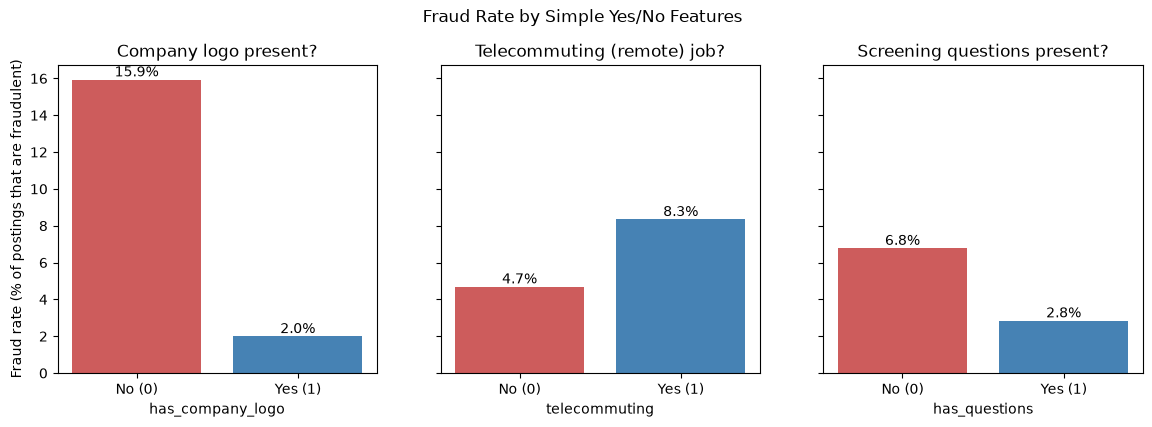

In [21]:
binary_columns = {
    "has_company_logo": "Company logo present?",
    "telecommuting": "Telecommuting (remote) job?",
    "has_questions": "Screening questions present?",
}

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)

for ax, (column_name, chart_title) in zip(axes, binary_columns.items()):
    fraud_rate = df.groupby(column_name)["fraudulent"].mean() * 100   # index is 0 and 1
    bars = ax.bar(["No (0)", "Yes (1)"], fraud_rate.values, color=["indianred", "steelblue"])
    ax.bar_label(bars, labels=[f"{value:.1f}%" for value in fraud_rate.values])
    ax.set_title(chart_title)
    ax.set_xlabel(column_name)

axes[0].set_ylabel("Fraud rate (% of postings that are fraudulent)")
fig.suptitle("Fraud Rate by Simple Yes/No Features", y=1.02)
fig.savefig(FIGURES_DIR / "fraud_rate_by_binary_features.png", dpi=150, bbox_inches="tight")
plt.show()

## 11. Key Findings

The first cell below **prints the key numbers straight from the dataset**, so nothing is typed in by hand. Interpretation follows in the next cell.

In [22]:
logo_rates = df.groupby("has_company_logo")["fraudulent"].mean() * 100
remote_rates = df.groupby("telecommuting")["fraudulent"].mean() * 100
questions_rates = df.groupby("has_questions")["fraudulent"].mean() * 100
missing_text_by_class = df[text_columns].isna().groupby(df["fraudulent"]).mean() * 100

print("DATASET SIZE")
print(f"  {df.shape[0]:,} job postings, {df.shape[1]} columns")
print()
print("TARGET AND CLASS BALANCE")
print(f"  Legitimate (0): {legitimate_count:,} ({legitimate_percent:.2f}%)")
print(f"  Fraudulent (1): {fraudulent_count:,} ({fraudulent_percent:.2f}%)")
print(f"  About {legitimate_count / fraudulent_count:.1f} legitimate postings for every 1 fraudulent posting")
print(f"  'Always say legitimate' would be right {legitimate_percent:.2f}% of the time and catch no fraud")
print()
print("MOST INCOMPLETE COLUMNS")
for column_name, row in missing_table.head(5).iterrows():
    print(f"  {column_name}: {row['missing_percent']:.1f}% missing")
print()
print("MISSING VALUES IN THE TEXT COLUMNS (all postings)")
for column_name in text_columns:
    print(f"  {column_name}: {df[column_name].isna().mean() * 100:.1f}% missing")
print()
print("MISSING TEXT, BY CLASS  (legitimate vs fraudulent)")
for column_name in text_columns:
    print(f"  {column_name}: {missing_text_by_class.loc[0, column_name]:.1f}% vs {missing_text_by_class.loc[1, column_name]:.1f}%")
print()
print("FRAUD RATE PATTERNS  (No/0  vs  Yes/1)")
print(f"  Company logo:         {logo_rates[0]:.1f}%  vs  {logo_rates[1]:.1f}%")
print(f"  Telecommuting:        {remote_rates[0]:.1f}%  vs  {remote_rates[1]:.1f}%")
print(f"  Screening questions:  {questions_rates[0]:.1f}%  vs  {questions_rates[1]:.1f}%")
print(f"  Postings without a logo are fraudulent {logo_rates[0] / logo_rates[1]:.1f} times as often as postings with a logo")
print()
print("HIGHEST FRAUD RATE INSIDE EACH CATEGORY COLUMN (groups with at least 100 postings)")
for column_name in ["employment_type", "required_experience", "required_education", "industry", "function"]:
    group_stats = df.groupby(column_name)["fraudulent"].agg(["count", "mean"])
    group_stats = group_stats[group_stats["count"] >= 100]
    top_group = group_stats["mean"].idxmax()
    print(f"  {column_name}: '{top_group}' -> {group_stats.loc[top_group, 'mean'] * 100:.1f}% "
          f"of {group_stats.loc[top_group, 'count']} postings")
print()
print("DUPLICATES")
print(f"  Exact duplicate rows (all columns):  {duplicates_with_id}")
print(f"  Duplicate rows ignoring job_id:      {duplicates_without_id} "
      f"({duplicates_without_id / len(df) * 100:.2f}% of rows)")

DATASET SIZE
  17,880 job postings, 18 columns

TARGET AND CLASS BALANCE
  Legitimate (0): 17,014 (95.16%)
  Fraudulent (1): 866 (4.84%)
  About 19.6 legitimate postings for every 1 fraudulent posting
  'Always say legitimate' would be right 95.16% of the time and catch no fraud

MOST INCOMPLETE COLUMNS
  salary_range: 84.0% missing
  department: 64.6% missing
  required_education: 45.3% missing
  benefits: 40.3% missing
  required_experience: 39.4% missing

MISSING VALUES IN THE TEXT COLUMNS (all postings)
  title: 0.0% missing
  company_profile: 18.5% missing
  description: 0.0% missing
  requirements: 15.1% missing
  benefits: 40.3% missing

MISSING TEXT, BY CLASS  (legitimate vs fraudulent)
  title: 0.0% vs 0.0%
  company_profile: 16.0% vs 67.8%
  description: 0.0% vs 0.1%
  requirements: 14.9% vs 17.8%
  benefits: 40.2% vs 42.0%

FRAUD RATE PATTERNS  (No/0  vs  Yes/1)
  Company logo:         15.9%  vs  2.0%
  Telecommuting:        4.7%  vs  8.3%
  Screening questions:  6.8%  vs  2

  employment_type: 'Part-time' -> 9.3% of 797 postings
  required_experience: 'Executive' -> 7.1% of 141 postings
  required_education: 'Certification' -> 11.2% of 170 postings
  industry: 'Oil & Energy' -> 38.0% of 287 postings
  function: 'Administrative' -> 18.9% of 630 postings

DUPLICATES
  Exact duplicate rows (all columns):  0
  Duplicate rows ignoring job_id:      281 (1.57% of rows)


### How to read these findings

All numbers above were calculated by the code from the real dataset. Here is what they mean in plain language.

**Dataset size.** Each row is one job posting and each column describes it. The first block gives the exact counts.

**Target variable.** `fraudulent` is the label we want to predict: `0` = legitimate, `1` = fraudulent. Predicting one of two classes is called **binary classification**.

**Class imbalance and why it matters.** Fraudulent postings are the **minority class**: look at how many legitimate postings there are for every fraudulent one. A lazy rule that always answers "legitimate" would still be right most of the time, yet it would catch no fraud at all. So **accuracy alone is not enough**. Later we will report, for the fraudulent class:
- **Precision** - when we say "fraud", how often are we right?
- **Recall** - how many of the real fraud postings do we catch?
- **F1-score** - a balance of precision and recall.
- **Confusion matrix** - a table showing correct and incorrect predictions per class.

**Missing values.** Some columns are mostly empty (see "most incomplete columns"). We will not use those as main features. The text columns are in much better shape: `title` and `description` are almost never missing, while `company_profile`, `requirements` and `benefits` are missing for some postings. Because a missing text field cannot be read by a model, we will replace it with an empty string later.

**Useful text columns.** `description` is the longest and most complete text, `requirements` and `company_profile` add more detail, and `title` is short but always present. `benefits` is the most often missing of the five. Together they are the best raw material for the NLP models.

**Interesting patterns (relationships, not causes).** In this dataset:
- Postings **without a company logo** have a much higher fraud rate than postings with one.
- Postings **without screening questions** have a higher fraud rate than postings with them.
- **Telecommuting** postings have a higher fraud rate than non-telecommuting ones, but there are far fewer of them.
- **Missing `company_profile`** is much more common among fraudulent postings than legitimate ones. In other words, *leaving a field blank* can itself be a clue.
- Be careful with small groups (a rate based on a handful of postings is not reliable).

These are patterns we can see, not proof that any one feature *causes* fraud.

**Duplicates.** No two rows are identical when `job_id` is included, but some postings repeat when `job_id` is ignored. They are a small share of the data, but they could leak between train and test sets, so we handle them before splitting.

**What this means for the next stage.**
1. Remove the duplicate postings first, then split into train and test sets using a **stratified** split so both sets keep the same fraud percentage.
2. Build one `combined_text` field from the five text columns, treating missing text as an empty string.
3. Judge every model with precision, recall, F1-score and the confusion matrix for the fraudulent class, not accuracy alone.
4. Wait for your review before starting Milestone 3.